# Tradutor de Textos com Transformer (PT→EN)
Deep Learning | UFPR

Baseado em: Vaswani et al. (2017) "Attention Is All You Need"

In [ ]:
# Dependencias devem ser instaladas via requirements.txt
# Exemplo:
# pip install -r requirements.txt

In [28]:
import collections
import logging
import os
import pathlib
import re
import string
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds
import tensorflow_text as text
import tensorflow as tf

## 1. Dataset e Tokenização

In [ ]:
import sys
import tensorflow_datasets as tfds

# A URL original do dataset saiu do ar, entao tive que usar um backup do Web Archive.
builder = tfds.builder("ted_hrlr_translate/pt_to_en")
sys.modules[builder.__module__]._DATA_URL = "https://web.archive.org/web/20240301220426/http://www.phontron.com/data/qi18naacl-dataset.tar.gz"

examples, metadata = tfds.load(
    "ted_hrlr_translate/pt_to_en",
    with_info=True,
    as_supervised=True
)
train_examples, val_examples = examples["train"], examples["validation"]

for pt_examples, en_examples in train_examples.batch(3).take(1):
    print("Exemplos em Português:")
    for pt in pt_examples.numpy():
        print(" ", pt.decode("utf-8"))
    print("\nExemplos em Inglês:")
    for en in en_examples.numpy():
        print(" ", en.decode("utf-8"))


Exemplos em Português:
  e quando melhoramos a procura , tiramos a única vantagem da impressão , que é a serendipidade .
  mas e se estes fatores fossem ativos ?
  mas eles não tinham a curiosidade de me testar .

Exemplos em Inglês:
  and when you improve searchability , you actually take away the one advantage of print , which is serendipity .
  but what if it were active ?
  but they did n't test for curiosity .


In [ ]:
model_name = "ted_hrlr_translate_pt_en_converter"
tf.keras.utils.get_file(
    f"{model_name}.zip",
    f"https://storage.googleapis.com/download.tensorflow.org/models/{model_name}.zip",
    cache_dir=".", cache_subdir="", extract=True
)

# Forca a descompactaco para evitar bugs do Colab com cache
import zipfile
with zipfile.ZipFile(f"{model_name}.zip", "r") as zip_ref:
    zip_ref.extractall(".")

tokenizers = tf.saved_model.load(model_name)

print("Tamanho vocabulário PT:", tokenizers.pt.get_vocab_size().numpy())
print("Tamanho vocabulário EN:", tokenizers.en.get_vocab_size().numpy())


Tamanho vocabulário PT: 7765
Tamanho vocabulário EN: 7010


In [18]:
BUFFER_SIZE = 20000
BATCH_SIZE = 64

def tokenize_pairs(pt, en):
    pt = tokenizers.pt.tokenize(pt).to_tensor()
    en = tokenizers.en.tokenize(en).to_tensor()
    return pt, en

def make_batches(ds):
    return (
        ds
        .cache()
        .shuffle(BUFFER_SIZE)
        .batch(BATCH_SIZE)
        .map(tokenize_pairs, num_parallel_calls=tf.data.AUTOTUNE)
        .prefetch(tf.data.AUTOTUNE)
    )

train_batches = make_batches(train_examples)
val_batches = make_batches(val_examples)

## 2. Componentes do Transformer

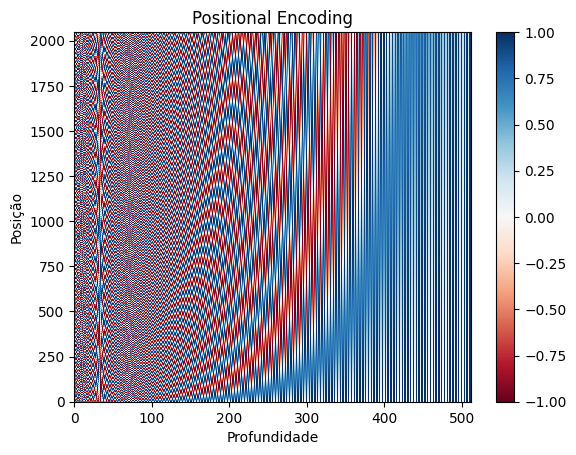

In [19]:
def get_angles(pos, i, d_model):
    angle_rates = 1 / np.power(10000, (2 * (i // 2)) / np.float32(d_model))
    return pos * angle_rates

def positional_encoding(position, d_model):
    angle_rads = get_angles(
        np.arange(position)[:, np.newaxis],
        np.arange(d_model)[np.newaxis, :],
        d_model
    )
    angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
    angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])
    return tf.cast(angle_rads[np.newaxis, ...], dtype=tf.float32)

def create_padding_mask(seq):
    seq = tf.cast(tf.math.equal(seq, 0), tf.float32)
    return seq[:, tf.newaxis, tf.newaxis, :]

def create_look_ahead_mask(size):
    return 1 - tf.linalg.band_part(tf.ones((size, size)), -1, 0)

# Visualizar positional encoding
n, d = 2048, 512
pos_encoding = positional_encoding(n, d)
plt.pcolormesh(pos_encoding[0], cmap='RdBu')
plt.xlabel('Profundidade')
plt.ylabel('Posição')
plt.colorbar()
plt.title('Positional Encoding')
plt.show()

In [20]:
def scaled_dot_product_attention(q, k, v, mask):
    matmul_qk = tf.matmul(q, k, transpose_b=True)
    dk = tf.cast(tf.shape(k)[-1], tf.float32)
    scaled_attention_logits = matmul_qk / tf.math.sqrt(dk)
    if mask is not None:
        scaled_attention_logits += (mask * -1e9)
    attention_weights = tf.nn.softmax(scaled_attention_logits, axis=-1)
    output = tf.matmul(attention_weights, v)
    return output, attention_weights

In [21]:
class MultiHeadAttention(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads):
        super(MultiHeadAttention, self).__init__()
        self.num_heads = num_heads
        self.d_model = d_model
        assert d_model % self.num_heads == 0
        self.depth = d_model // self.num_heads
        self.wq = tf.keras.layers.Dense(d_model)
        self.wk = tf.keras.layers.Dense(d_model)
        self.wv = tf.keras.layers.Dense(d_model)
        self.dense = tf.keras.layers.Dense(d_model)

    def split_heads(self, x, batch_size):
        x = tf.reshape(x, (batch_size, -1, self.num_heads, self.depth))
        return tf.transpose(x, perm=[0, 2, 1, 3])

    def call(self, v, k, q, mask):
        batch_size = tf.shape(q)[0]
        q = self.split_heads(self.wq(q), batch_size)
        k = self.split_heads(self.wk(k), batch_size)
        v = self.split_heads(self.wv(v), batch_size)
        scaled_attention, attention_weights = scaled_dot_product_attention(q, k, v, mask)
        scaled_attention = tf.transpose(scaled_attention, perm=[0, 2, 1, 3])
        concat_attention = tf.reshape(scaled_attention, (batch_size, -1, self.d_model))
        return self.dense(concat_attention), attention_weights

In [22]:
def point_wise_feed_forward_network(d_model, dff):
    return tf.keras.Sequential([
        tf.keras.layers.Dense(dff, activation='relu'),
        tf.keras.layers.Dense(d_model)
    ])

class EncoderLayer(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, dff, rate=0.1):
        super(EncoderLayer, self).__init__()
        self.mha = MultiHeadAttention(d_model, num_heads)
        self.ffn = point_wise_feed_forward_network(d_model, dff)
        self.layernorm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = tf.keras.layers.Dropout(rate)
        self.dropout2 = tf.keras.layers.Dropout(rate)

    def call(self, x, training=False, mask=None):
        attn_output, _ = self.mha(x, x, x, mask)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(x + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

class DecoderLayer(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, dff, rate=0.1):
        super(DecoderLayer, self).__init__()
        self.mha1 = MultiHeadAttention(d_model, num_heads)
        self.mha2 = MultiHeadAttention(d_model, num_heads)
        self.ffn = point_wise_feed_forward_network(d_model, dff)
        self.layernorm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.layernorm3 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = tf.keras.layers.Dropout(rate)
        self.dropout2 = tf.keras.layers.Dropout(rate)
        self.dropout3 = tf.keras.layers.Dropout(rate)

    def call(self, x, enc_output, training=False, look_ahead_mask=None, padding_mask=None):
        attn1, attn_weights_block1 = self.mha1(x, x, x, look_ahead_mask)
        out1 = self.layernorm1(self.dropout1(attn1, training=training) + x)
        attn2, attn_weights_block2 = self.mha2(enc_output, enc_output, out1, padding_mask)
        out2 = self.layernorm2(self.dropout2(attn2, training=training) + out1)
        ffn_output = self.ffn(out2)
        out3 = self.layernorm3(self.dropout3(ffn_output, training=training) + out2)
        return out3, attn_weights_block1, attn_weights_block2


## 3. Modelo Transformer Completo

In [23]:
class Encoder(tf.keras.layers.Layer):
    def __init__(self, num_layers, d_model, num_heads, dff,
                 input_vocab_size, maximum_position_encoding, rate=0.1):
        super(Encoder, self).__init__()
        self.d_model = d_model
        self.num_layers = num_layers
        self.embedding = tf.keras.layers.Embedding(input_vocab_size, d_model)
        self.pos_encoding = positional_encoding(maximum_position_encoding, d_model)
        self.enc_layers = [EncoderLayer(d_model, num_heads, dff, rate) for _ in range(num_layers)]
        self.dropout = tf.keras.layers.Dropout(rate)

    def call(self, x, training=False, mask=None):
        seq_len = tf.shape(x)[1]
        x = self.embedding(x)
        x *= tf.math.sqrt(tf.cast(self.d_model, tf.float32))
        x += self.pos_encoding[:, :seq_len, :]
        x = self.dropout(x, training=training)
        for enc_layer in self.enc_layers:
            x = enc_layer(x, training=training, mask=mask)
        return x

class Decoder(tf.keras.layers.Layer):
    def __init__(self, num_layers, d_model, num_heads, dff,
                 target_vocab_size, maximum_position_encoding, rate=0.1):
        super(Decoder, self).__init__()
        self.d_model = d_model
        self.num_layers = num_layers
        self.embedding = tf.keras.layers.Embedding(target_vocab_size, d_model)
        self.pos_encoding = positional_encoding(maximum_position_encoding, d_model)
        self.dec_layers = [DecoderLayer(d_model, num_heads, dff, rate) for _ in range(num_layers)]
        self.dropout = tf.keras.layers.Dropout(rate)

    def call(self, x, enc_output, training=False, look_ahead_mask=None, padding_mask=None):
        seq_len = tf.shape(x)[1]
        attention_weights = {}
        x = self.embedding(x)
        x *= tf.math.sqrt(tf.cast(self.d_model, tf.float32))
        x += self.pos_encoding[:, :seq_len, :]
        x = self.dropout(x, training=training)
        for i, dec_layer in enumerate(self.dec_layers):
            x, block1, block2 = dec_layer(
                x, enc_output,
                training=training,
                look_ahead_mask=look_ahead_mask,
                padding_mask=padding_mask
            )
            attention_weights[f'decoder_layer{i+1}_block1'] = block1
            attention_weights[f'decoder_layer{i+1}_block2'] = block2
        return x, attention_weights

class Transformer(tf.keras.Model):
    def __init__(self, num_layers, d_model, num_heads, dff, input_vocab_size,
                 target_vocab_size, pe_input, pe_target, rate=0.1):
        super().__init__()
        self.encoder = Encoder(num_layers, d_model, num_heads, dff,
                               input_vocab_size, pe_input, rate)
        self.decoder = Decoder(num_layers, d_model, num_heads, dff,
                               target_vocab_size, pe_target, rate)
        self.final_layer = tf.keras.layers.Dense(target_vocab_size)

    def call(self, inputs, training=False):
        inp, tar = inputs
        enc_padding_mask, look_ahead_mask, dec_padding_mask = self.create_masks(inp, tar)
        enc_output = self.encoder(inp, training=training, mask=enc_padding_mask)
        dec_output, attention_weights = self.decoder(
            tar, enc_output,
            training=training,
            look_ahead_mask=look_ahead_mask,
            padding_mask=dec_padding_mask
        )
        return self.final_layer(dec_output), attention_weights

    def create_masks(self, inp, tar):
        enc_padding_mask = create_padding_mask(inp)
        dec_padding_mask = create_padding_mask(inp)
        look_ahead_mask = create_look_ahead_mask(tf.shape(tar)[1])
        dec_target_padding_mask = create_padding_mask(tar)
        look_ahead_mask = tf.maximum(dec_target_padding_mask, look_ahead_mask)
        return enc_padding_mask, look_ahead_mask, dec_padding_mask


## 4. Hiperparâmetros, Loss e Otimizador

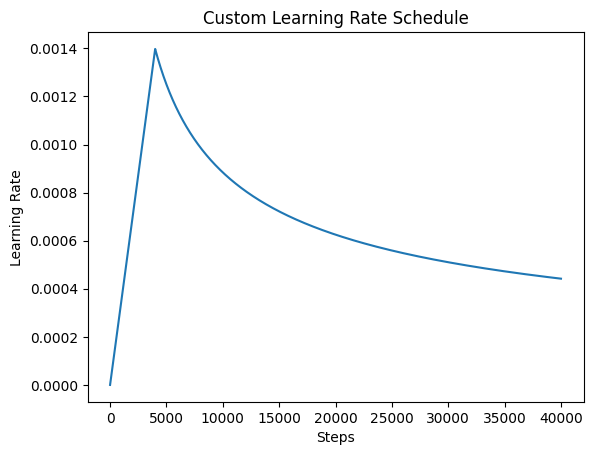

In [24]:
num_layers = 4
d_model = 128
dff = 512
num_heads = 8
dropout_rate = 0.1
EPOCHS = 20

class CustomSchedule(tf.keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, d_model, warmup_steps=4000):
        super(CustomSchedule, self).__init__()
        self.d_model = tf.cast(d_model, tf.float32)
        self.warmup_steps = warmup_steps

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        arg1 = tf.math.rsqrt(step)
        arg2 = step * (self.warmup_steps ** -1.5)
        return tf.math.rsqrt(self.d_model) * tf.math.minimum(arg1, arg2)

learning_rate = CustomSchedule(d_model)
optimizer = tf.keras.optimizers.Adam(learning_rate, beta_1=0.9, beta_2=0.98, epsilon=1e-9)

# Visualizar o schedule
temp_learning_rate_schedule = CustomSchedule(d_model)
plt.plot(temp_learning_rate_schedule(tf.cast(tf.range(40000), dtype=tf.float32)))
plt.ylabel('Learning Rate')
plt.xlabel('Steps')
plt.title('Custom Learning Rate Schedule')
plt.show()

# Loss com mascara de padding
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction='none')

def loss_function(real, pred):
    mask = tf.math.logical_not(tf.math.equal(real, 0))
    loss_ = loss_object(real, pred)
    mask = tf.cast(mask, dtype=loss_.dtype)
    loss_ *= mask
    return tf.reduce_sum(loss_) / tf.reduce_sum(mask)

def accuracy_function(real, pred):
    accuracies = tf.equal(real, tf.argmax(pred, axis=2))
    mask = tf.math.logical_not(tf.math.equal(real, 0))
    accuracies = tf.math.logical_and(mask, accuracies)
    accuracies = tf.cast(accuracies, dtype=tf.float32)
    mask = tf.cast(mask, dtype=tf.float32)
    return tf.reduce_sum(accuracies) / tf.reduce_sum(mask)

train_loss = tf.keras.metrics.Mean(name='train_loss')
train_accuracy = tf.keras.metrics.Mean(name='train_accuracy')

In [25]:
transformer = Transformer(
    num_layers=num_layers,
    d_model=d_model,
    num_heads=num_heads,
    dff=dff,
    input_vocab_size=int(tokenizers.pt.get_vocab_size()),
    target_vocab_size=int(tokenizers.en.get_vocab_size()),
    pe_input=1000,
    pe_target=1000,
    rate=dropout_rate
)

checkpoint_path = './checkpoints/train'
ckpt = tf.train.Checkpoint(transformer=transformer, optimizer=optimizer)
ckpt_manager = tf.train.CheckpointManager(ckpt, checkpoint_path, max_to_keep=5)

if ckpt_manager.latest_checkpoint:
    ckpt.restore(ckpt_manager.latest_checkpoint)
    print('Checkpoint restaurado!')

## 5. Treinamento

In [26]:
train_step_signature = [
    tf.TensorSpec(shape=(None, None), dtype=tf.int64),
    tf.TensorSpec(shape=(None, None), dtype=tf.int64),
]

@tf.function(input_signature=train_step_signature)
def train_step(inp, tar):
    tar_inp = tar[:, :-1]   # Teacher forcing: entrada do decoder
    tar_real = tar[:, 1:]   # Saida esperada
    with tf.GradientTape() as tape:
        predictions, _ = transformer([inp, tar_inp], training=True)
        loss = loss_function(tar_real, predictions)
    gradients = tape.gradient(loss, transformer.trainable_variables)
    optimizer.apply_gradients(zip(gradients, transformer.trainable_variables))
    train_loss(loss)
    train_accuracy(accuracy_function(tar_real, predictions))

for epoch in range(EPOCHS):
    start = time.time()
    train_loss.reset_state()
    train_accuracy.reset_state()
    for batch, (inp, tar) in enumerate(train_batches):
        train_step(inp, tar)
        if batch % 50 == 0:
            print(f'Época {epoch+1} Batch {batch} Loss {train_loss.result():.4f} Acuracia {train_accuracy.result():.4f}')
    if (epoch + 1) % 5 == 0:
        ckpt_save_path = ckpt_manager.save()
        print(f'Salvando checkpoint epoca {epoch+1}: {ckpt_save_path}')
    print(f'Epoca {epoch+1} Loss {train_loss.result():.4f} Acuracia {train_accuracy.result():.4f}')
    print(f'Tempo: {time.time()-start:.2f}s\n')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'encoder_layer_4' (of type EncoderLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'encoder_layer_5' (of type EncoderLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'encoder_layer_6' (of type EncoderLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/usr/lo

Época 1 Batch 0 Loss 8.8889 Acuracia 0.0000
Época 1 Batch 50 Loss 8.8330 Acuracia 0.0017
Época 1 Batch 100 Loss 8.7177 Acuracia 0.0238
Época 1 Batch 150 Loss 8.5961 Acuracia 0.0329
Época 1 Batch 200 Loss 8.4504 Acuracia 0.0383
Época 1 Batch 250 Loss 8.2776 Acuracia 0.0441
Época 1 Batch 300 Loss 8.0860 Acuracia 0.0547
Época 1 Batch 350 Loss 7.8890 Acuracia 0.0638
Época 1 Batch 400 Loss 7.7012 Acuracia 0.0718
Época 1 Batch 450 Loss 7.5301 Acuracia 0.0791
Época 1 Batch 500 Loss 7.3846 Acuracia 0.0854
Época 1 Batch 550 Loss 7.2483 Acuracia 0.0921
Época 1 Batch 600 Loss 7.1235 Acuracia 0.0980
Época 1 Batch 650 Loss 7.0088 Acuracia 0.1040
Época 1 Batch 700 Loss 6.9022 Acuracia 0.1102
Época 1 Batch 750 Loss 6.8049 Acuracia 0.1157
Época 1 Batch 800 Loss 6.7129 Acuracia 0.1212
Epoca 1 Loss 6.6970 Acuracia 0.1222
Tempo: 203.21s

Época 2 Batch 0 Loss 5.1819 Acuracia 0.2187
Época 2 Batch 50 Loss 5.2468 Acuracia 0.2122
Época 2 Batch 100 Loss 5.2113 Acuracia 0.2154
Época 2 Batch 150 Loss 5.1725 Acur

## 6. Tradução (Inferência Autorregressiva)

In [27]:
class Translator(tf.Module):
    def __init__(self, tokenizers, transformer):
        self.tokenizers = tokenizers
        self.transformer = transformer

    def __call__(self, sentence, max_length=50):
        if isinstance(sentence, str):
            sentence = tf.constant(sentence)
        if len(sentence.shape) == 0:
            sentence = sentence[tf.newaxis]
        sentence = self.tokenizers.pt.tokenize(sentence).to_tensor()
        encoder_input = sentence
        start_end = self.tokenizers.en.tokenize([''])[0]
        start = start_end[0][tf.newaxis]
        end = start_end[1][tf.newaxis]
        output_array = tf.TensorArray(dtype=tf.int64, size=0, dynamic_size=True)
        output_array = output_array.write(0, start)
        for i in tf.range(max_length):
            output = tf.transpose(output_array.stack())
            predictions, _ = self.transformer([encoder_input, output], training=False)
            predicted_id = tf.argmax(predictions[:, -1:, :], axis=-1)
            output_array = output_array.write(i + 1, predicted_id[0])
            if predicted_id == end:
                break
        output = tf.transpose(output_array.stack())
        text_out = self.tokenizers.en.detokenize(output)[0]
        tokens_out = self.tokenizers.en.lookup(output)[0]
        _, attention_weights = self.transformer([encoder_input, output[:, :-1]], training=False)
        return text_out, tokens_out, attention_weights


translator = Translator(tokenizers, transformer)

# Testar traducoes
testes = [
    'Eu li sobre triceratops na enciclopédia.',
    'Este é um problema muito difícil.',
    'Meu nome é João.',
    'O céu está azul hoje.',
]

for sentence in testes:
    translated_text, translated_tokens, attention_weights = translator(sentence)
    print(f'PT: {sentence}')
    print(f'EN: {translated_text.numpy().decode("utf-8")}\n')

PT: Eu li sobre triceratops na enciclopédia.
EN: i read about threpoose on the encyclopedia .

PT: Este é um problema muito difícil.
EN: this is a very difficult problem .

PT: Meu nome é João.
EN: my name is jo joeh .

PT: O céu está azul hoje.
EN: the sky is blue today .

